# Client selection with volatile clients

Comparison of E3CS, clipped-entropy OSMD, and uniform random selection on EMNIST-Letters or CIFAR-10.

Each round selects 20 of 100 clients. Methods share the client data, initial model, local epochs, and simulated success outcomes for each seed. Random selects without replacement and runs once per setting, since it has no fairness schedule.



## Setup

In [1]:
import argparse
import copy
import random
import sys
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision.datasets import CIFAR10, EMNIST

K = 100
K_SELECTED = 20
DATA_PER_CLIENT = 500
BATCH_SIZE = 40
LOCAL_LR = 0.01
MOMENTUM = 0.9
PROXIMAL_COEFFICIENT = 0.5
PAPER_ROUNDS = {"emnist": 400, "cifar10": 2500}
TINY = np.finfo(np.float64).tiny


## Client sampling

In [2]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def fairness_quota(schedule, round_index, total_rounds):
    if schedule == "inc":
        return (
            0.0
            if round_index < total_rounds // 4
            else K_SELECTED / K
        )
    return float(schedule) * K_SELECTED / K

def bounded_entropy_allocation(
    log_weights,
    total,
    lower,
    upper=1.0,
    additive_baseline=False,
):
    
    log_weights = np.asarray(log_weights, dtype=np.float64)

    if log_weights.ndim != 1:
        raise ValueError("log_weights must be one-dimensional.")
    if not np.all(np.isfinite(log_weights)):
        raise ValueError("log_weights must be finite.")

    n = len(log_weights)

    if not n * lower - 1e-10 <= total <= n * upper + 1e-10:
        raise ValueError("Infeasible probability constraints.")

    if np.isclose(total, n * lower, atol=1e-12, rtol=0):
        return np.full(n, lower), np.zeros(n, dtype=bool)

    if np.isclose(total, n * upper, atol=1e-12, rtol=0):
        return np.full(n, upper), np.zeros(n, dtype=bool)

    shifted = log_weights - log_weights.max()

    def evaluate(log_c):
        z = shifted + log_c

        if additive_baseline:
            cap = upper - lower
            return lower + np.exp(
                np.clip(z, -745.0, np.log(cap))
            )

        return np.maximum(
            lower,
            np.exp(np.clip(z, -745.0, np.log(upper))),
        )

    lo = -50.0
    hi = max(50.0, -float(shifted.min()) + 50.0)

    for _ in range(110):
        mid = (lo + hi) / 2.0
        if evaluate(mid).sum() < total:
            lo = mid
        else:
            hi = mid

    log_c = (lo + hi) / 2.0
    p = evaluate(log_c)

    overflow = (
        shifted + log_c > np.log(upper - lower) + 1e-12
        if additive_baseline
        else np.zeros(n, dtype=bool)
    )

    if abs(p.sum() - total) > 1e-8:
        raise FloatingPointError("Probability sum constraint failed.")
    if np.any(p < lower - 1e-10):
        raise FloatingPointError("Lower probability bound failed.")
    if np.any(p > upper + 1e-10):
        raise FloatingPointError("Upper probability bound failed.")

    return p, overflow

def pivotal_sample(probabilities, sample_size, rng):
    """Fixed-size dependent rounding preserving inclusion marginals."""
    q = np.asarray(probabilities, dtype=np.float64).copy()

    if abs(q.sum() - sample_size) > 1e-7:
        raise ValueError("Probabilities must sum to the sample size.")

    q = np.clip(q, 0.0, 1.0)
    tolerance = 1e-12

    while True:
        fractional = np.flatnonzero(
            (q > tolerance) & (q < 1.0 - tolerance)
        )
        if len(fractional) < 2:
            break

        i, j = rng.choice(fractional, size=2, replace=False)
        a = min(1.0 - q[i], q[j])
        b = min(q[i], 1.0 - q[j])

        if rng.random() < b / (a + b):
            q[i] += a
            q[j] -= a
        else:
            q[i] -= b
            q[j] += b

        q[i] = np.clip(q[i], 0.0, 1.0)
        q[j] = np.clip(q[j], 0.0, 1.0)

    selected = np.flatnonzero(q > 0.5)

    if len(selected) != sample_size:
        raise FloatingPointError("Incorrect dependent-rounding sample size.")

    return selected

def sample_clients(probabilities, sampler, rng):
    if sampler == "pivotal":
        return pivotal_sample(probabilities, K_SELECTED, rng)

    generator = torch.Generator(device="cpu")
    generator.manual_seed(int(rng.integers(0, 2**63 - 1)))

    return torch.multinomial(
        torch.as_tensor(probabilities, dtype=torch.float64),
        K_SELECTED,
        replacement=False,
        generator=generator,
    ).numpy()

def random_clients(rng):
  
    return rng.choice(K, size=K_SELECTED, replace=False)


## E3CS and OSMD

In [3]:
class E3CS:
    def __init__(self, eta):
        self.eta = eta
        self.log_weights = np.zeros(K, dtype=np.float64)
        self.overflow = np.zeros(K, dtype=bool)

    def probabilities(self, sigma):
        p, self.overflow = bounded_entropy_allocation(
            self.log_weights,
            total=K_SELECTED,
            lower=sigma,
            additive_baseline=True,
        )
        return p

    def update(self, selected, outcomes, probabilities, sigma):
        estimated_reward = np.zeros(K, dtype=np.float64)
        estimated_reward[selected] = (
            outcomes / np.maximum(probabilities[selected], TINY)
        )

        rate = self.eta * (K_SELECTED - K * sigma) / K
        self.log_weights[~self.overflow] += (
            rate * estimated_reward[~self.overflow]
        )
        self.log_weights -= self.log_weights.max()

class OSMD:
    def __init__(self, eta, rate_mode):
        self.eta = eta
        self.rate_mode = rate_mode
        self.p = np.full(K, K_SELECTED / K, dtype=np.float64)

    def probabilities(self, sigma):
        self.p, _ = bounded_entropy_allocation(
            np.log(np.maximum(self.p, TINY)),
            total=K_SELECTED,
            lower=sigma,
        )
        return self.p.copy()

    def update(self, selected, outcomes, probabilities, sigma):
        estimated_loss = np.zeros(K, dtype=np.float64)
        estimated_loss[selected] = (
            (1.0 - outcomes)
            / np.maximum(probabilities[selected], TINY)
        )

        rate = self.eta
        if self.rate_mode == "matched":
            rate *= (K_SELECTED - K * sigma) / K

        log_intermediate = (
            np.log(np.maximum(probabilities, TINY))
            - rate * estimated_loss
        )

        self.p, _ = bounded_entropy_allocation(
            log_intermediate,
            total=K_SELECTED,
            lower=sigma,
        )

## Data and local training

In [4]:
class PaperCNN(nn.Module):
    def __init__(self, dataset):
        super().__init__()

        if dataset == "emnist":
            in_channels, channels, image_size = 1, 10, 28
            hidden1, hidden2, classes = 1280, 256, 26
        else:
            in_channels, channels, image_size = 3, 64, 32
            hidden1, hidden2, classes = 384, 192, 10

        self.features = nn.Sequential(
            nn.Conv2d(in_channels, channels, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(channels, channels, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        with torch.no_grad():
            flat_size = self.features(
                torch.zeros(1, in_channels, image_size, image_size)
            ).numel()

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_size, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

def load_dataset(name, root):
    if name == "emnist":
        dataset = EMNIST(
            root=root,
            split="letters",
            train=True,
            download=True,
        )
        images = dataset.data.unsqueeze(1).contiguous()
        labels = dataset.targets.long() - 1

    elif name == "cifar10":
        dataset = CIFAR10(root=root, train=True, download=True)
        images = (
            torch.from_numpy(dataset.data)
            .permute(0, 3, 1, 2)
            .contiguous()
        )
        labels = torch.as_tensor(dataset.targets, dtype=torch.long)

    else:
        raise ValueError(f"Unknown dataset: {name}")

    return images, labels

def make_clients(labels, distribution, seed, split_mode="global"):
    if split_mode == "global":
        return make_clients_global(labels, distribution, seed)
    #Clients independently sample data; overlap across clients is allowed
    rng = np.random.default_rng(seed)
    labels_np = labels.numpy()
    classes = np.unique(labels_np)
    all_indices = np.arange(len(labels_np))

    class_pools = {
        label: np.flatnonzero(labels_np == label)
        for label in classes
    }
    other_pools = {
        label: np.flatnonzero(labels_np != label)
        for label in classes
    }

    clients = []

    for _ in range(K):
        if distribution == "iid":
            indices = rng.choice(
                all_indices, size=DATA_PER_CLIENT, replace=False
            )
        else:
            primary = int(rng.choice(classes))
            primary_count = int(0.8 * DATA_PER_CLIENT)

            primary_indices = rng.choice(
                class_pools[primary],
                size=primary_count,
                replace=False,
            )
            other_indices = rng.choice(
                other_pools[primary],
                size=DATA_PER_CLIENT - primary_count,
                replace=False,
            )
            indices = np.concatenate([primary_indices, other_indices])

        rng.shuffle(indices)
        test_count = DATA_PER_CLIENT // 10

        clients.append({
            "test": torch.as_tensor(
                indices[:test_count], dtype=torch.long
            ),
            "train": torch.as_tensor(
                indices[test_count:], dtype=torch.long
            ),
        })

    return clients

def make_clients_global(labels, distribution, seed):
    #Sample client data from globally disjoint training and test pools
    rng = np.random.default_rng(seed)
    labels_np = np.asarray(labels)
    classes = np.unique(labels_np)
    train_pool, test_pool = [], []
    for label in classes:
        pool = rng.permutation(np.flatnonzero(labels_np == label))
        cut = max(1, len(pool) // 10)
        test_pool.extend(pool[:cut])
        train_pool.extend(pool[cut:])
    train_pool, test_pool = np.array(train_pool), np.array(test_pool)
    clients = []
    for _ in range(K):
        primary = rng.choice(classes)
        def draw(pool, size):
            if distribution == "iid":
                return rng.choice(pool, size=size, replace=False)
            a = pool[labels_np[pool] == primary]
            b = pool[labels_np[pool] != primary]
            n_primary = int(0.8 * size)
            indices = np.concatenate((rng.choice(a, n_primary, replace=False),
                                      rng.choice(b, size-n_primary, replace=False)))
            return rng.permutation(indices)
        clients.append({"train": draw(train_pool, 450), "test": draw(test_pool, 50)})
    # A test image must not be used for training by any client.
    train_ids = np.unique(np.concatenate([c["train"] for c in clients]))
    test_ids = np.unique(np.concatenate([c["test"] for c in clients]))
    assert np.intersect1d(train_ids, test_ids).size == 0
    return clients

def local_train(
    global_model,
    images,
    labels,
    indices,
    epochs,
    update,
    device,
    batch_seed,
):
    local_model = copy.deepcopy(global_model)
    local_model.train()

    optimizer = torch.optim.SGD(
        local_model.parameters(),
        lr=LOCAL_LR,
        momentum=MOMENTUM,
    )
    criterion = nn.CrossEntropyLoss()

    reference = None
    if update == "fedprox":
        reference = [
            p.detach().clone() for p in global_model.parameters()
        ]

    generator = torch.Generator(device="cpu")
    generator.manual_seed(batch_seed)

    for _ in range(int(epochs)):
        order = indices[
            torch.randperm(len(indices), generator=generator)
        ]

        for start in range(0, len(order), BATCH_SIZE):
            batch = order[start:start + BATCH_SIZE]

            x = images[batch].to(
                device=device, dtype=torch.float32
            ) / 255.0
            y = labels[batch].to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(local_model(x), y)

            if reference is not None:
                proximal = sum(
                    (parameter - initial).square().sum()
                    for parameter, initial in zip(
                        local_model.parameters(), reference
                    )
                )
                loss += PROXIMAL_COEFFICIENT * proximal / 2

            loss.backward()
            optimizer.step()

    return local_model

@torch.no_grad()
def evaluate(model, images, labels, indices, device, batch_size=512):
    model.eval()
    correct, total = 0, 0

    for start in range(0, len(indices), batch_size):
        batch = indices[start:start + batch_size]

        x = images[batch].to(
            device=device, dtype=torch.float32
        ) / 255.0
        y = labels[batch].to(device)

        prediction = model(x).argmax(dim=1)
        correct += int((prediction == y).sum().item())
        total += len(batch)

    return correct / total

## Federated training

In [5]:
def run_method(
    args,
    dataset,
    distribution,
    update,
    seed,
    schedule,
    method,
    images,
    labels,
    clients,
    initial_state,
    success_table,
    local_epochs,
    device,
):
    rounds = len(success_table)
    model = PaperCNN(dataset).to(device)
    model.load_state_dict(initial_state)

    if method == "E3CS":
        selector = E3CS(args.eta)
    elif method == "OSMD":
        eta = args.eta if args.osmd_eta is None else args.osmd_eta
        selector = OSMD(eta, args.osmd_rate)
    elif method == "Random":
        selector = None
    else:
        raise ValueError(f"Unknown selection method: {method}")

    selection_rng = np.random.default_rng(seed + 123456)
    test_indices = torch.cat([client["test"] for client in clients])

    cumulative_successes = 0
    history = []

    for t in range(rounds):
        if method == "Random":
            # Uniform sampling needs no fairness schedule or weight updates.
            selected = random_clients(selection_rng)
            sigma = K_SELECTED / K
        else:
            sigma = fairness_quota(schedule, t, rounds)
            probabilities = selector.probabilities(sigma)
            selected = sample_clients(probabilities, args.sampler, selection_rng)

        outcomes = success_table[t, selected].astype(np.float64)
        successful_clients = selected[outcomes.astype(bool)]

        cumulative_successes += len(successful_clients)

        base_parameters = [
            p.detach().clone() for p in model.parameters()
        ]
        aggregated_deltas = [
            torch.zeros_like(p) for p in base_parameters
        ]

        for client_id in successful_clients:
            client_id = int(client_id)
            batch_seed = (
                seed * 1000003 + t * K + client_id
            ) % (2**63 - 1)

            local_model = local_train(
                global_model=model,
                images=images,
                labels=labels,
                indices=clients[client_id]["train"],
                epochs=local_epochs[client_id],
                update=update,
                device=device,
                batch_seed=batch_seed,
            )

            with torch.no_grad():
                for delta, local_parameter, base in zip(
                    aggregated_deltas,
                    local_model.parameters(),
                    base_parameters,
                ):
                    delta.add_(
                        local_parameter - base,
                        alpha=1.0 / K,
                    )

            del local_model

        with torch.no_grad():
            for parameter, base, delta in zip(
                model.parameters(),
                base_parameters,
                aggregated_deltas,
            ):
                parameter.copy_(base + delta)

        if selector is not None:
            selector.update(selected, outcomes, probabilities, sigma)

        should_evaluate = (
            (t + 1) % args.eval_every == 0
            or t == 0
            or t + 1 == rounds
        )

        accuracy = (
            evaluate(model, images, labels, test_indices, device)
            if should_evaluate
            else np.nan
        )

        history.append({
            "dataset": dataset,
            "distribution": distribution,
            "update": update,
            "seed": seed,
            "method": method,
            "schedule": schedule,
            "round": t + 1,
            "sigma": sigma,
            "accuracy": accuracy,
            "successful_this_round": len(successful_clients),
            "cep": cumulative_successes,
            "success_ratio":
                cumulative_successes / ((t + 1) * K_SELECTED),
        })

        if (
            (t + 1) % args.log_every == 0
            or t == 0
            or t + 1 == rounds
        ):
            accuracy_text = (
                f"{accuracy:.4f}"
                if np.isfinite(accuracy)
                else "not evaluated"
            )
            print(
                f"{dataset:7s} {distribution:6s} {update:7s} "
                f"seed={seed} {method:5s}-{schedule:3s} "
                f"round={t + 1:4d}/{rounds} "
                f"accuracy={accuracy_text} "
                f"CEP={cumulative_successes}",
                flush=True,
            )

    return pd.DataFrame(history)

## Results and plots

In [6]:
def make_summary(history):
    group_columns = [
        "dataset", "distribution", "update",
        "seed", "method", "schedule",
    ]
    rows = []

    for keys, frame in history.groupby(group_columns, sort=False):
        frame = frame.sort_values("round")
        evaluated = frame.dropna(subset=["accuracy"])

        row = dict(zip(group_columns, keys))
        row["final_accuracy_percent"] = (
            100 * evaluated.iloc[-1]["accuracy"]
        )
        row["final_cep"] = int(frame.iloc[-1]["cep"])
        row["final_success_ratio"] = (
            frame.iloc[-1]["success_ratio"]
        )

        thresholds = (
            [0.65, 0.75, 0.85]
            if row["dataset"] == "emnist"
            else [0.45, 0.55, 0.65]
        )

        for threshold in thresholds:
            reached = evaluated[
                evaluated["accuracy"] >= threshold
            ]
            column = (
                f"round_at_{int(round(100 * threshold))}_percent"
            )
            row[column] = (
                int(reached.iloc[0]["round"])
                if len(reached)
                else np.nan
            )

        rows.append(row)

    return pd.DataFrame(rows)

def display_image(path):
    try:
        from IPython.display import Image, display
        display(Image(filename=str(path)))
    except ImportError:
        pass

def compare_methods(summary):
    #Summarize final performance across seeds for each experiment
    keys = ["dataset", "distribution", "update", "method", "schedule"]
    return summary.groupby(keys, sort=False).agg(
        seeds=("seed", "nunique"),
        accuracy_mean=("final_accuracy_percent", "mean"),
        accuracy_std=("final_accuracy_percent", "std"),
        cep_mean=("final_cep", "mean"),
        cep_std=("final_cep", "std"),
    ).reset_index()


def plot_results(history, output_dir, show=False):
    """Plot accuracy and participation, with one random baseline per setting."""
    schedules = [s for s in history["schedule"].unique() if s != "uniform"]
    colors = {s: plt.get_cmap("tab10")(i) for i, s in enumerate(schedules)}
    styles = {"E3CS": "-", "OSMD": "--", "Random": ":"}

    for setting, frame in history.groupby(["dataset", "distribution", "update"], sort=False):
        prefix = "_".join(setting)
        for metric, label in [("accuracy", "Test accuracy (%)"),
                              ("cep", "Cumulative effective participation")]:
            fig, ax = plt.subplots(figsize=(10, 6))
            for (method, schedule), runs in frame.groupby(["method", "schedule"], sort=False):
                stats = runs.dropna(subset=[metric]).groupby("round")[metric].agg(
                    ["mean", "std", "count"]
                )
                scale = 100 if metric == "accuracy" else 1
                x = stats.index.to_numpy()
                mean = stats["mean"].to_numpy() * scale
                std = stats["std"].fillna(0).to_numpy() * scale
                color = "0.25" if method == "Random" else colors[schedule]
                name = "Random" if method == "Random" else f"{method}-{schedule}"
                ax.plot(x, mean, label=name, color=color, linestyle=styles[method], lw=2)
                if (stats["count"] > 1).any():
                    ax.fill_between(x, mean - std, mean + std, color=color, alpha=0.1)

            ax.set(xlabel="Communication round", ylabel=label,
                   title=" | ".join(setting))
            ax.grid(alpha=0.2)
            ax.legend(ncol=2, fontsize=9)
            if metric == "accuracy":
                ax.set_ylim(0, 100)
            if frame["seed"].nunique() > 1:
                fig.text(0.5, 0.01, "Shading: one standard deviation across seeds",
                         ha="center", fontsize=9)
            fig.tight_layout(rect=(0, 0.03, 1, 1))
            path = output_dir / f"{prefix}_{metric}.png"
            fig.savefig(path, dpi=160)
            plt.close(fig)
            if show:
                display_image(path)


## Experiment runner

In [7]:
def parse_args(argv=None):
    parser = argparse.ArgumentParser(
        description="Compare E3CS, OSMD, and random client selection.",
        allow_abbrev=False,
    )
    parser.add_argument(
        "--datasets", nargs="+",
        choices=["emnist", "cifar10"],
        default=["emnist"],
    )
    parser.add_argument(
        "--distributions", nargs="+",
        choices=["iid", "noniid"],
        default=["noniid"],
    )
    parser.add_argument(
        "--updates", nargs="+",
        choices=["fedavg", "fedprox"],
        default=["fedavg"],
    )
    parser.add_argument(
        "--schedules", nargs="+",
        choices=["0", "0.5", "0.8", "inc"],
        default=["0", "0.5", "0.8", "inc"],
    )
    parser.add_argument("--seeds", nargs="+", type=int, default=[0, 1, 2])
    parser.add_argument("--split-mode", choices=["global", "paper-local"], default="global",
                        help="Global holdout prevents cross-client train/test leakage.")
    parser.add_argument("--eta", type=float, default=0.5)
    parser.add_argument("--osmd-eta", type=float, default=None,
                        help="Separate OSMD rate; defaults to --eta.")
    parser.add_argument(
        "--osmd-rate",
        choices=["matched", "constant"],
        default="matched",
    )
    parser.add_argument(
        "--sampler",
        choices=["pivotal", "paper"],
        default="pivotal",
    )
    parser.add_argument(
        "--rounds", type=int, default=None,
        help="Defaults: EMNIST=400; CIFAR-10=2500.",
    )
    parser.add_argument("--eval-every", type=int, default=1)
    parser.add_argument("--log-every", type=int, default=20)
    parser.add_argument("--data-dir", default="./data")
    parser.add_argument("--output-dir", default="./results")
    parser.add_argument(
        "--device",
        default="cuda" if torch.cuda.is_available() else "cpu",
    )
    parser.add_argument("--cpu-threads", type=int, default=4)
    parser.add_argument(
        "--show-plots",
        action="store_true",
        help="Display final separate figures inline in a notebook.",
    )

    args = parser.parse_args(argv)

    if args.rounds is not None and args.rounds < 1:
        parser.error("--rounds must be positive.")
    if args.eval_every < 1 or args.log_every < 1:
        parser.error("Evaluation/logging intervals must be positive.")
    if args.cpu_threads < 1:
        parser.error("--cpu-threads must be positive.")
    if not 0 < args.eta < 1:
        parser.error("--eta must be between zero and one.")
    if args.osmd_eta is not None and args.osmd_eta <= 0:
        parser.error("--osmd-eta must be positive.")
    if len(set(args.seeds)) != len(args.seeds):
        parser.error("Seeds must be unique.")
    if len(set(args.schedules)) != len(args.schedules):
        parser.error("Schedules must be unique.")
    if any(seed < 0 for seed in args.seeds):
        parser.error("Seeds must be nonnegative.")

    return args

def save_results(history, output_dir):
    summary = make_summary(history)
    history.to_csv(output_dir / "history.csv", index=False)
    summary.to_csv(output_dir / "summary.csv", index=False)
    return summary


def main(argv=None):
    args = parse_args(argv)
    torch.set_num_threads(args.cpu_threads)
    device = torch.device(args.device)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA was requested but is unavailable.")

    output_dir = Path(args.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if args.sampler == "paper":
        warnings.warn("Paper sampling does not preserve the inclusion probabilities "
                      "used in the importance-weighted updates.")
    if args.eval_every != 1:
        warnings.warn("Accuracy targets are checked only at evaluation rounds.")

    histories = []
    for dataset in args.datasets:
        print(f"Loading {dataset}...", flush=True)
        images, labels = load_dataset(dataset, args.data_dir)
        rounds = args.rounds if args.rounds is not None else PAPER_ROUNDS[dataset]

        for distribution in args.distributions:
            for seed in args.seeds:
                clients = make_clients(labels, distribution, seed, args.split_mode)
                clients = [{key: torch.as_tensor(value, dtype=torch.long)
                            for key, value in client.items()} for client in clients]
                if args.split_mode == "paper-local":
                    warnings.warn("Local holdouts can overlap other clients' training data.")

                rng = np.random.default_rng(seed + 987654)
                success_rates = np.repeat([0.1, 0.3, 0.6, 0.9], K // 4)
                local_epochs = rng.integers(1, 5, size=K)
                success_table = rng.random((rounds, K)) < success_rates[None, :]

                seed_everything(seed)
                initial_model = PaperCNN(dataset)
                initial_state = copy.deepcopy(initial_model.state_dict())
                del initial_model

                for update in args.updates:
                    # Random is independent of the fairness quota, so run it once.
                    experiments = [("Random", "uniform")]
                    experiments += [(method, schedule) for schedule in args.schedules
                                    for method in ["E3CS", "OSMD"]]
                    for method, schedule in experiments:
                        history = run_method(
                            args, dataset, distribution, update, seed, schedule, method,
                            images, labels, clients, initial_state, success_table,
                            local_epochs, device,
                        )
                        histories.append(history)
                        # Save after each run so completed work survives an interruption.
                        save_results(pd.concat(histories, ignore_index=True), output_dir)

    history = pd.concat(histories, ignore_index=True)
    summary = save_results(history, output_dir)
    plot_results(history, output_dir, show=args.show_plots)
    print("\nFinal comparison (accuracy in percent):")
    print(compare_methods(summary).round(3).to_string(index=False, na_rep="—"))
    print(f"\nResults saved to {output_dir.resolve()}")
    return history, summary


## Run the experiment

You can change the parameters below to suit your experiment, including the dataset, data distribution, local update method, fairness schedules, random seeds, and output folder.

Leave `--rounds` unset for 400 EMNIST rounds or 2500 CIFAR-10 rounds. Add `--rounds 2` for a short execution check.

Loading emnist...


100%|██████████| 562M/562M [00:01<00:00, 318MB/s]


emnist  noniid fedavg  seed=0 Random-uniform round=   1/400 accuracy=0.0486 CEP=8
emnist  noniid fedavg  seed=0 Random-uniform round=  20/400 accuracy=0.1110 CEP=204
emnist  noniid fedavg  seed=0 Random-uniform round=  40/400 accuracy=0.1190 CEP=378
emnist  noniid fedavg  seed=0 Random-uniform round=  60/400 accuracy=0.1552 CEP=575
emnist  noniid fedavg  seed=0 Random-uniform round=  80/400 accuracy=0.2940 CEP=769
emnist  noniid fedavg  seed=0 Random-uniform round= 100/400 accuracy=0.3250 CEP=965
emnist  noniid fedavg  seed=0 Random-uniform round= 120/400 accuracy=0.3864 CEP=1143
emnist  noniid fedavg  seed=0 Random-uniform round= 140/400 accuracy=0.4762 CEP=1333
emnist  noniid fedavg  seed=0 Random-uniform round= 160/400 accuracy=0.5442 CEP=1529
emnist  noniid fedavg  seed=0 Random-uniform round= 180/400 accuracy=0.6072 CEP=1719
emnist  noniid fedavg  seed=0 Random-uniform round= 200/400 accuracy=0.6598 CEP=1936
emnist  noniid fedavg  seed=0 Random-uniform round= 220/400 accuracy=0.68

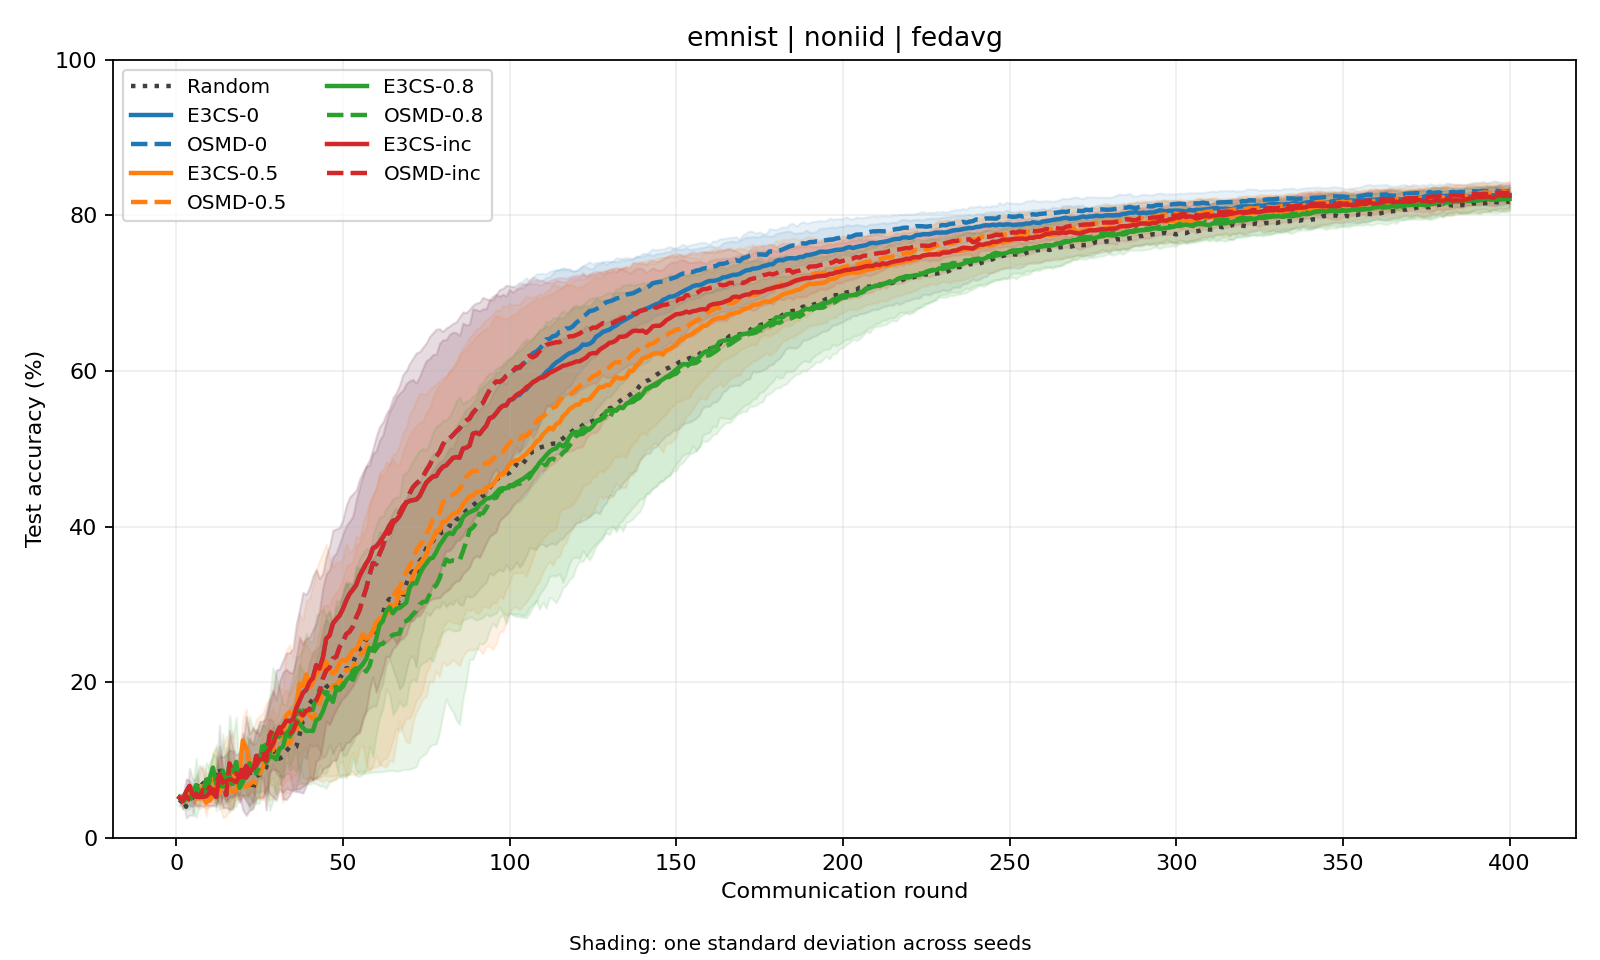

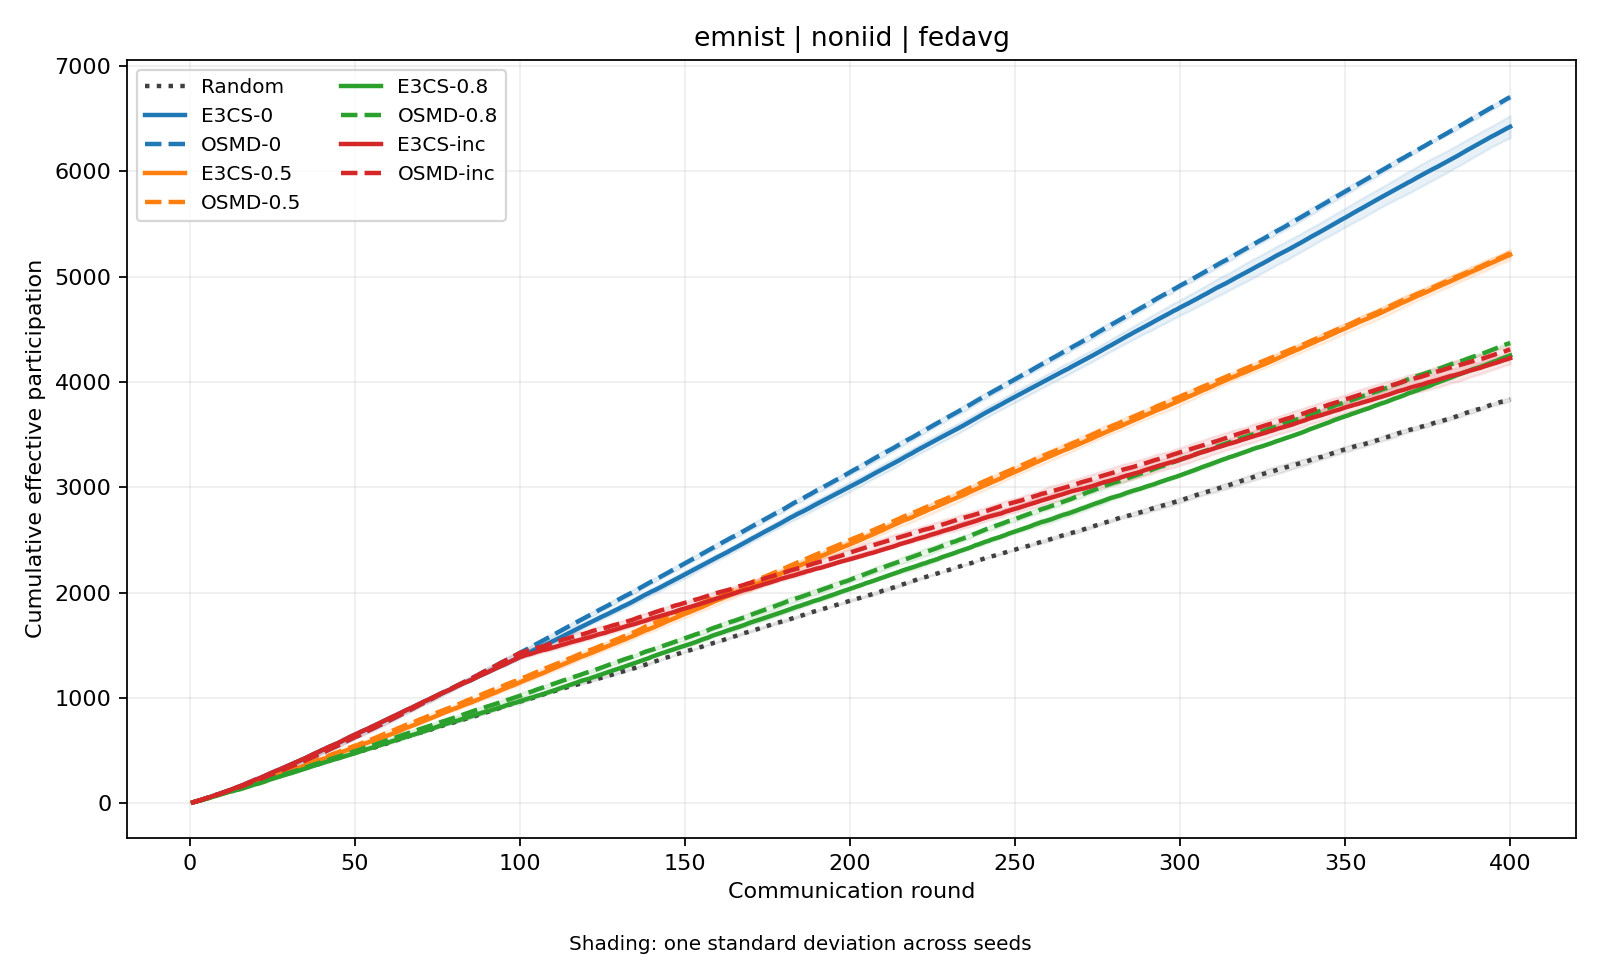


Final comparison (accuracy in percent):
dataset distribution update method schedule  seeds  accuracy_mean  accuracy_std  cep_mean  cep_std
 emnist       noniid fedavg Random  uniform      3         81.780         1.054  3836.333   17.098
 emnist       noniid fedavg   E3CS        0      3         82.640         1.115  6422.667  104.006
 emnist       noniid fedavg   OSMD        0      3         83.147         1.093  6703.333   19.553
 emnist       noniid fedavg   E3CS      0.5      3         82.440         1.561  5208.000   47.823
 emnist       noniid fedavg   OSMD      0.5      3         82.973         1.436  5221.667   33.501
 emnist       noniid fedavg   E3CS      0.8      3         82.120         1.593  4251.333   19.296
 emnist       noniid fedavg   OSMD      0.8      3         82.287         1.171  4370.333    8.386
 emnist       noniid fedavg   E3CS      inc      3         82.527         0.991  4226.333   54.602
 emnist       noniid fedavg   OSMD      inc      3         82.947   

In [8]:
NOTEBOOK_ARGS = [
    "--datasets", "emnist",
    "--distributions", "noniid",
    "--updates", "fedavg",
    "--schedules", "0", "0.5", "0.8", "inc",
    "--seeds", "0", "1", "2",
    "--output-dir", "./results",
    "--show-plots",
]

history_df, summary_df = main(NOTEBOOK_ARGS)


## Compare methods

The table reports mean final accuracy and CEP, with sample standard deviations across seeds. A standard deviation is unavailable for a single seed. `summary.csv` also records the first evaluated round reaching each accuracy target; an empty entry means the target was not reached.


In [9]:
from IPython.display import display

display(compare_methods(summary_df).round(3))
display(summary_df)


,dataset,distribution,update,method,schedule,seeds,accuracy_mean,accuracy_std,cep_mean,cep_std
0,emnist,noniid,fedavg,Random,uniform,3,81.780,1.054,3836.333,17.098
1,emnist,noniid,fedavg,E3CS,0,3,82.640,1.115,6422.667,104.006
2,emnist,noniid,fedavg,OSMD,0,3,83.147,1.093,6703.333,19.553
3,emnist,noniid,fedavg,E3CS,0.5,3,82.440,1.561,5208.000,47.823
4,emnist,noniid,fedavg,OSMD,0.5,3,82.973,1.436,5221.667,33.501
5,emnist,noniid,fedavg,E3CS,0.8,3,82.120,1.593,4251.333,19.296
6,emnist,noniid,fedavg,OSMD,0.8,3,82.287,1.171,4370.333,8.386
7,emnist,noniid,fedavg,E3CS,inc,3,82.527,0.991,4226.333,54.602
8,emnist,noniid,fedavg,OSMD,inc,3,82.947,1.035,4310.667,41.004


,dataset,distribution,update,seed,method,schedule,final_accuracy_percent,final_cep,final_success_ratio,round_at_65_percent,round_at_75_percent,round_at_85_percent
0,emnist,noniid,fedavg,0,Random,uniform,81.52,3825,0.478125,197,270,NaN
1,emnist,noniid,fedavg,0,E3CS,0,82.32,6304,0.788000,154,216,NaN
2,emnist,noniid,fedavg,0,OSMD,0,83.60,6722,0.840250,137,199,NaN
3,emnist,noniid,fedavg,0,E3CS,0.5,81.62,5225,0.653125,189,263,NaN
4,emnist,noniid,fedavg,0,OSMD,0.5,82.66,5192,0.649000,182,246,NaN
5,emnist,noniid,fedavg,0,E3CS,0.8,80.98,4236,0.529500,209,279,NaN
6,emnist,noniid,fedavg,0,OSMD,0.8,81.22,4380,0.547500,210,275,NaN
7,emnist,noniid,fedavg,0,E3CS,inc,82.10,4189,0.523625,179,256,NaN
8,emnist,noniid,fedavg,0,OSMD,inc,83.06,4358,0.544750,158,231,NaN
9,emnist,noniid,fedavg,1,Random,uniform,82.94,3828,0.478500,139,227,NaN
